<a href="https://colab.research.google.com/github/solasobambo-prog/ts-data-science/blob/main/week5a.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## INFERENCE BASICS

Part 1: Population, sample, and the wobble

A population is everyone you care about. A sample is the part you actually hold.
A parameter describes the population (unknown). A statistic describes the sample (computable, always slightly off).
A second sample would give a slightly different average. That spread is sampling variability, and it shrinks as sample size grows, roughly with the square root of n.
The central limit theorem says that even when your column is skewed, the distribution of sample means is roughly normal. Business data like revenue is always skewed, so this is what lets us use the standard tools.

Part 2: Covariance and correlation

Covariance shows how two variables move together, but its units are awkward.
Pearson r rescales it to between -1 and +1, so anyone can read it.
Two traps: correlation only sees linear links, so always plot a scatter, and correlation is not causation. You may say "moves with", never "because".

In [1]:
import os
import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

# Load the Module 4 Movies dataset
path = kagglehub.dataset_download("danielgrijalvas/movies")
csv_file = next(f for f in os.listdir(path) if f.endswith('.csv'))
movies = pd.read_csv(os.path.join(path, csv_file))
raw_copy = movies.copy()

# Create clean millions-scale columns for readable axes and covariance units
movies['gross_m'] = movies['gross'] / 1e6
movies['budget_m'] = movies['budget'] / 1e6
movies['votes_m'] = movies['votes'] / 1e6

def finish(ax, title, xlabel, ylabel):
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    sns.despine(ax=ax)

n_rows, n_cols = movies.shape
print(f"Loaded movies dataset: {n_rows:,} rows, {n_cols} columns")


C:\Users\USER\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loaded movies dataset: 7,668 rows, 18 columns


=== PART 1 & 2: SAMPLING DISTRIBUTION OF THE MEAN (n = 50) ===


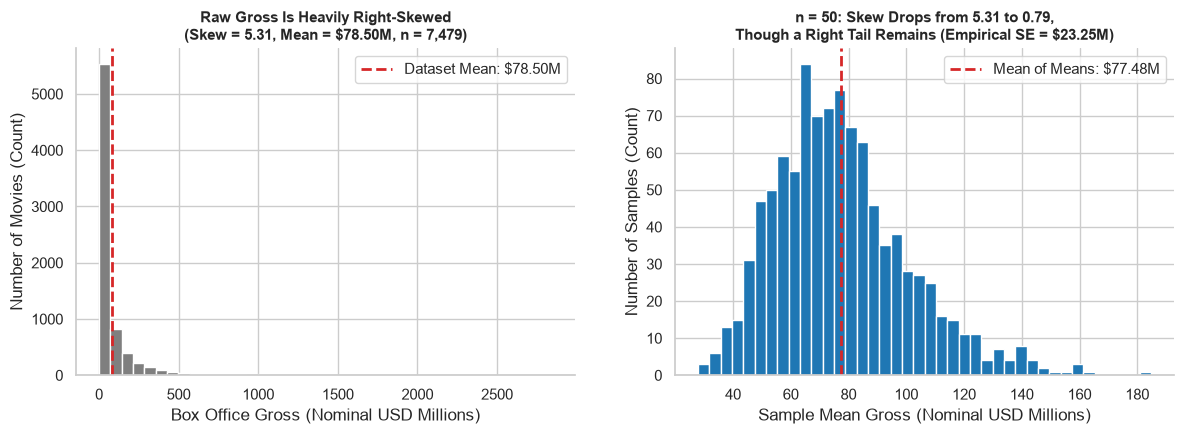

Bootstrap Source (n=7,479) -> Mean: $78.50M | SD: $165.73M | Skew: 5.31
Sample Means (n=50)       -> Mean: $77.48M | Empirical SE: $23.25M (Theoretical SE: $23.44M) | Skew: 0.79


In [2]:
print("=== PART 1 & 2: SAMPLING DISTRIBUTION OF THE MEAN (n = 50) ===")

# --- ORIGINAL PREDICTION (n = 50 — UNEDITED) ---
# Prediction (n = 50): Even though raw box office gross ('gross_m') is heavily right-skewed (skew > 5) with a long tail past $2,800M, drawing 1,000 bootstrap sample means of size n = 50 will produce a roughly bell-shaped (normal) sampling distribution centered near the population mean (~$78.5M), with standard error roughly sigma / sqrt(50) (~128 / 7.07 ≈ $18M).

col = movies['gross_m'].dropna()
emp_pop_mean = float(col.mean())
emp_pop_std = float(col.std(ddof=1))
emp_pop_skew = float(col.skew())

# 1. Draw 1,000 bootstrap samples of size 50 and record each mean
rng = np.random.default_rng(42)
means_50 = np.array([rng.choice(col, size=50, replace=True).mean() for _ in range(1000)])

se_50_emp = float(means_50.std(ddof=1))
se_50_theo = emp_pop_std / np.sqrt(50)
skew_50 = float(pd.Series(means_50).skew())

# 2. Compare the shape of the raw column with the shape of the sample means
fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(12, 4.5))

ax_left.hist(col, bins=40, color='#7f7f7f', edgecolor='white')
ax_left.axvline(emp_pop_mean, color='#d62728', linestyle='--', linewidth=2, label=f'Dataset Mean: \\${emp_pop_mean:.2f}M')
finish(
    ax_left,
    f'Raw Gross Is Heavily Right-Skewed\n(Skew = {emp_pop_skew:.2f}, Mean = \\${emp_pop_mean:.2f}M, n = {len(col):,})',
    'Box Office Gross (Nominal USD Millions)',
    'Number of Movies (Count)'
)
ax_left.legend()

ax_right.hist(means_50, bins=40, color='#1f77b4', edgecolor='white')
ax_right.axvline(means_50.mean(), color='#d62728', linestyle='--', linewidth=2, label=f'Mean of Means: \\${means_50.mean():.2f}M')
finish(
    ax_right,
    f'n = 50: Skew Drops from {emp_pop_skew:.2f} to {skew_50:.2f},\nThough a Right Tail Remains (Empirical SE = \\${se_50_emp:.2f}M)',
    'Sample Mean Gross (Nominal USD Millions)',
    'Number of Samples (Count)'
)
ax_right.legend()

fig.tight_layout(w_pad=3.0)
plt.show()

print(f"Bootstrap Source (n={len(col):,}) -> Mean: ${emp_pop_mean:.2f}M | SD: ${emp_pop_std:.2f}M | Skew: {emp_pop_skew:.2f}")
print(f"Sample Means (n=50)       -> Mean: ${means_50.mean():.2f}M | Empirical SE: ${se_50_emp:.2f}M (Theoretical SE: ${se_50_theo:.2f}M) | Skew: {skew_50:.2f}")

# Result check (n = 50): Ratio/center held, with two informative misses — (1) predicted SE ~$18M using an assumed SD of ~$128M, but actual col.std() is $165.73M, yielding empirical SE = $23.25M (theoretical $23.44M); (2) at n = 50, skew drops sharply from 5.31 to 0.79, but a visible right tail still remains rather than full symmetry.


=== BREAK IT ON PURPOSE: SAMPLE SIZE n = 10 vs. n = 50 vs. n = 500 ===


,sample_size_n,mean_of_means,empirical_se,theoretical_se,skewness,min_sample_mean,max_sample_mean
0,10,77.87,50.61,52.41,1.42,6.87,404.27
1,50,77.48,23.25,23.44,0.79,27.87,184.88
2,500,78.40,7.58,7.41,0.31,56.05,112.10


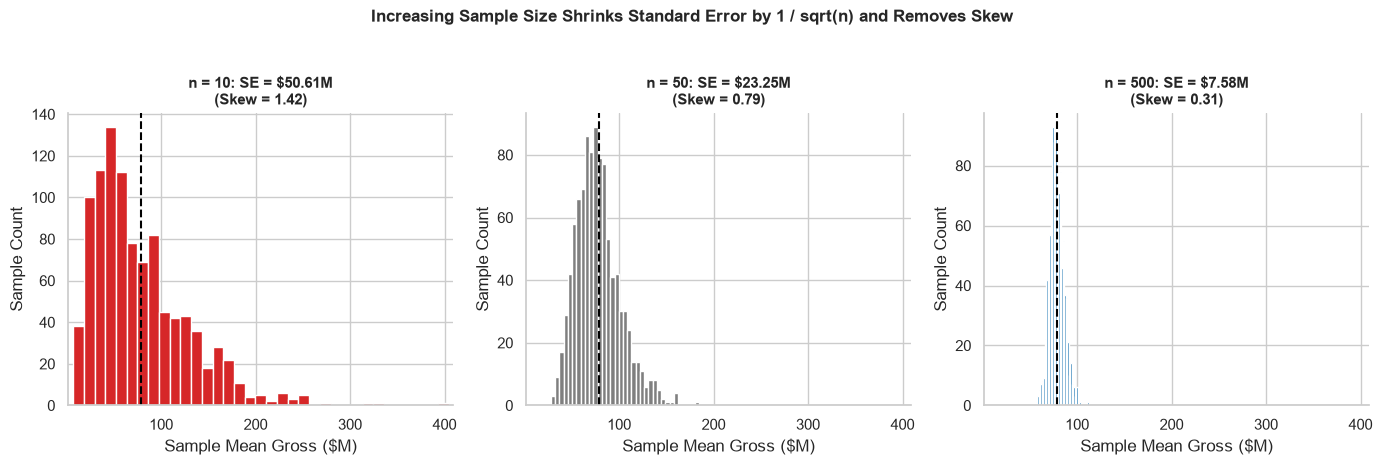

In [3]:
print("=== BREAK IT ON PURPOSE: SAMPLE SIZE n = 10 vs. n = 50 vs. n = 500 ===")

# --- ORIGINAL PREDICTION (BREAKING SAMPLE SIZE — UNEDITED) ---
# Prediction (n = 10 vs. n = 500):
# 1. Shrinking sample size from n = 50 to n = 10 will make the histogram much WIDER (larger standard error, roughly sqrt(5) ≈ 2.24x wider, around $40M) AND noticeably right-skewed again because 10 films is too small to average out single blockbuster outliers.
# 2. Increasing sample size from n = 50 to n = 500 will make the histogram much NARROWER (smaller standard error, roughly 1/sqrt(10) ≈ 0.32x as wide, around $5.7M) and tightly symmetric around the $78.5M population mean.

rng_break = np.random.default_rng(42)
means_10 = np.array([rng_break.choice(col, size=10, replace=True).mean() for _ in range(1000)])
means_500 = np.array([rng_break.choice(col, size=500, replace=True).mean() for _ in range(1000)])

sample_sizes = list((10, 50, 500))
summary_clt = pd.DataFrame({
    'sample_size_n': sample_sizes,
    'mean_of_means': [means_10.mean(), means_50.mean(), means_500.mean()],
    'empirical_se': [means_10.std(ddof=1), means_50.std(ddof=1), means_500.std(ddof=1)],
    'theoretical_se': [emp_pop_std / np.sqrt(10), emp_pop_std / np.sqrt(50), emp_pop_std / np.sqrt(500)],
    'skewness': [pd.Series(means_10).skew(), pd.Series(means_50).skew(), pd.Series(means_500).skew()],
    'min_sample_mean': [means_10.min(), means_50.min(), means_500.min()],
    'max_sample_mean': [means_10.max(), means_50.max(), means_500.max()],
})
display(summary_clt.round(2))

# Plot all three on the EXACT SAME X-AXIS SCALE so the width contraction is visually unmistakable
x_low = min(means_10.min(), means_50.min(), means_500.min()) - 5
x_high = max(means_10.max(), means_50.max(), means_500.max()) + 5

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(14, 4.5), sharex=True)

for ax, m_arr, n_sz, clr in zip(
    (ax1, ax2, ax3),
    (means_10, means_50, means_500),
    sample_sizes,
    ('#d62728', '#7f7f7f', '#1f77b4')
):
    se_val = float(m_arr.std(ddof=1))
    sk_val = float(pd.Series(m_arr).skew())
    ax.hist(m_arr, bins=35, color=clr, edgecolor='white')
    ax.axvline(emp_pop_mean, color='black', linestyle='--', linewidth=1.5)
    ax.set_xlim(x_low, x_high)
    finish(
        ax,
        f'n = {n_sz}: SE = \\${se_val:.2f}M\n(Skew = {sk_val:.2f})',
        'Sample Mean Gross ($M)',
        'Sample Count'
    )

fig.suptitle('Increasing Sample Size Shrinks Standard Error by 1 / sqrt(n) and Removes Skew', y=1.03, fontsize=12, fontweight='bold')
fig.tight_layout()
fig.savefig('clt_sample_size_comparison.png', dpi=200)
plt.show()

# Result check (n = 10 vs. n = 500): Scaling ratios held, while absolute SEs were higher than predicted ($50.61M vs. ~$40M at n = 10; $7.58M vs. ~$5.7M at n = 500) because the initial guess used SD ≈ $128M instead of the actual col.std() = $165.73M (theoretical SEs: $52.41M at n = 10 and $7.41M at n = 500). At n = 500, skewness drops to 0.31 and the distribution finally looks symmetric/bell-shaped.


=== PART 3: COVARIANCE, CORRELATION & THE LINEAR TRAP ===
Complete rows across ['gross_m', 'budget_m', 'votes_m', 'score']: n = 5,436

--- Covariance Matrix (Unit-Dependent) ---


,gross_m,budget_m,votes_m,score
gross_m,35008.32,5755.67,21.20,40.03
budget_m,5755.67,1726.21,3.37,2.87
votes_m,21.20,3.37,0.03,0.08
score,40.03,2.87,0.08,0.93



--- Correlation Matrix (Unit-Free, -1 to +1) ---


,gross_m,budget_m,votes_m,score
gross_m,1.000,0.740,0.615,0.222
budget_m,0.740,1.000,0.440,0.072
votes_m,0.615,0.440,1.000,0.474
score,0.222,0.072,0.474,1.000


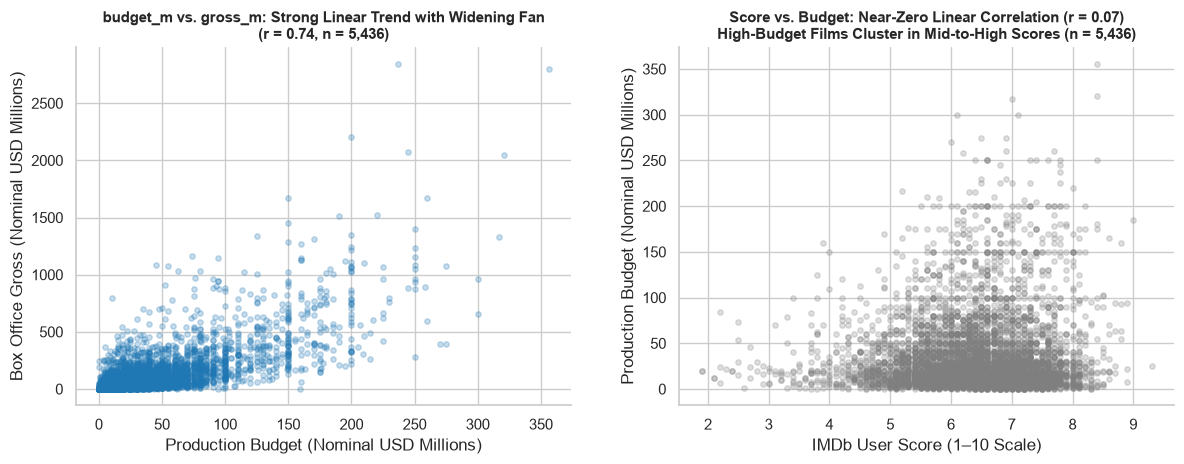

In [4]:
print("=== PART 3: COVARIANCE, CORRELATION & THE LINEAR TRAP ===")

# --- ORIGINAL PREDICTION (PART 3 — UNEDITED) ---
# Prediction (Part 3): Among ['gross_m', 'budget_m', 'votes_m', 'score'], 'budget_m' and 'gross_m' will have the strongest positive covariance and correlation (r around 0.74), while 'score' will show near-zero linear correlation with 'budget_m' (r < 0.10). Plotting the scatter chart will confirm whether the relationship is genuinely linear or if extreme outliers / non-linear curves distort r.

num_cols = ['gross_m', 'budget_m', 'votes_m', 'score']
num = movies[num_cols].dropna()

print(f"Complete rows across {num_cols}: n = {len(num):,}")
print("\n--- Covariance Matrix (Unit-Dependent) ---")
display(num.cov().round(2))

print("\n--- Correlation Matrix (Unit-Free, -1 to +1) ---")
corr_mat = num.corr()
display(corr_mat.round(3))

# Compute strongest correlation pair dynamically from upper triangle
upper_pairs = corr_mat.where(np.triu(np.ones(corr_mat.shape, dtype=bool), k=1)).stack()
best_pair = upper_pairs.abs().idxmax()
best_r = float(upper_pairs[best_pair])
col_a, col_b = best_pair

fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(12, 4.8))

# Left: Strongest linear pair (budget_m vs gross_m) showing widening fan
ax_left.scatter(num['budget_m'], num['gross_m'], alpha=0.25, s=15, color='#1f77b4')
finish(
    ax_left,
    f'{col_b} vs. {col_a}: Strong Linear Trend with Widening Fan\n(r = {best_r:.2f}, n = {len(num):,})',
    'Production Budget (Nominal USD Millions)',
    'Box Office Gross (Nominal USD Millions)'
)

# Right: Non-linear / weak pair (score vs budget_m) guarding against assuming r tells the whole story
r_score_budget = float(corr_mat.loc['score', 'budget_m'])
ax_right.scatter(num['score'], num['budget_m'], alpha=0.25, s=15, color='#7f7f7f')
finish(
    ax_right,
    f'Score vs. Budget: Near-Zero Linear Correlation (r = {r_score_budget:.2f})\nHigh-Budget Films Cluster in Mid-to-High Scores (n = {len(num):,})',
    'IMDb User Score (1–10 Scale)',
    'Production Budget (Nominal USD Millions)'
)

fig.tight_layout(w_pad=3.0)
plt.show()

# Result check (Part 3): Predicted ('budget_m', 'gross_m') strongest (r ~ 0.74) and score vs budget < 0.10; actual strongest pair is ('gross_m', 'budget_m') at r = 0.740 (cov = 5,755.67, n = 5,436), followed by ('gross_m', 'votes_m') at r = 0.615 (cov = 21.20), while ('score', 'budget_m') is r = 0.072 (cov = 2.87).


### Methodological Note: Bootstrap Sampling Frame

* **Dataset as Empirical Population:** In Cells 2 and 3, we draw samples with replacement (`replace=True`) from the **7,479 films** with valid gross in our dataset. Strictly speaking, those 7,479 films are themselves a sample of all historical film releases rather than the true universal population—so this simulation operates as a **non-parametric bootstrap** where the observed dataset serves as our empirical sampling frame.

---

### Check Yourself Before Moving On

1. **Parameter vs. Statistic (and Which One We Actually Compute):**
   * A **parameter** is a fixed, usually unknown numerical summary describing an entire **population** (such as the true population mean $\mu$ or population standard deviation $\sigma$).
   * A **statistic** is a known numerical summary computed directly from a **sample** of data (such as a sample mean $\bar{x}$ or sample standard deviation $s$).
   * **Which one we actually compute:** In practice, we compute **statistics** from observed sample data (such as our bootstrap sample means and empirical standard errors) to estimate and quantify uncertainty around unknown population parameters.

2. **Revenue and Ad Spend Correlate at $r = 0.85$ — What You May Conclude vs. What You May Not:**
   * **What you MAY conclude:** There is a **strong, positive linear association** between ad spend and revenue within the observed sample—observations with higher ad spend tend to coincide with higher revenue along a roughly straight-line pattern.
   * **What you MAY NOT conclude (Two Limits):**
     1. **No Causation:** You cannot conclude that increasing ad spend *causes* revenue to rise; confounding factors (such as seasonal demand or product launches) or reverse causality could drive both variables.
     2. **No Extrapolation Beyond Sample Range:** You cannot assume the linear relationship ($r = 0.85$) continues to hold outside the range of ad spend observed in your sample (for example, diminishing returns or market saturation at much higher spend levels).
